
# HW2：多元線性回歸分析 — 洪水機率預測

## 1. Business Understanding（商業理解）

### 研究背景
洪水可能造成生命與財產損失，因此了解影響洪水發生機率的因素具有重要意義。本研究使用 Kaggle 公開的 Flood Prediction Dataset，透過機器學習分析不同因素與洪水機率之間的關係。

### 研究目標
本研究希望使用多元線性回歸模型，根據 20 個輸入特徵預測洪水發生機率（FloodProbability）。

### 研究問題
1. 多元線性回歸能否有效預測洪水機率？
2. 使用全部 20 個特徵與選擇 15 個特徵，哪種模型表現較好？
3. 哪些特徵與洪水機率具有較強的線性關聯？

### 評估方式
使用 MAE、MSE、RMSE 和 R² 評估模型表現，並繪製實際值與預測值比較圖，以及 95% 預測區間圖。

### 研究限制
本研究使用 Kaggle 競賽資料，分析結果主要用於比較回歸模型與特徵選擇方法，不能直接當作實際洪水預警系統。



## 2. Data Understanding（資料理解）

### 資料集來源
本研究使用 Kaggle 的 Regression with a Flood Prediction Dataset。

資料來源：
https://www.kaggle.com/competitions/playground-series-s4e5/data

### 資料集介紹
本資料集包含 1,117,957 筆訓練資料，共有 22 個欄位，其中包含 20 個輸入特徵、1 個資料編號（id）以及 1 個預測目標（FloodProbability）。

### 資料檢查結果
1. 資料筆數：1,117,957 筆。
2. 輸入特徵：20 個。
3. 預測目標：FloodProbability。
4. 缺失值：所有欄位皆為 0。
5. 資料型態：21 個整數欄位及 1 個浮點數欄位。

### 初步分析
經過資料檢查，本資料集沒有缺失值，因此不需要進行缺失值填補。

所有輸入特徵皆為數值型態，適合使用多元線性回歸進行分析。


In [19]:

import pandas as pd

# 讀取 Kaggle 洪水預測資料集
df = pd.read_csv('/content/train.csv')

# 查看資料集大小
print("資料集大小：", df.shape)

# 查看前 5 筆資料
display(df.head())


資料集大小： (1117957, 22)


,id,MonsoonIntensity,TopographyDrainage,RiverManagement,Deforestation,Urbanization,ClimateChange,DamsQuality,Siltation,AgriculturalPractices,...,DrainageSystems,CoastalVulnerability,Landslides,Watersheds,DeterioratingInfrastructure,PopulationScore,WetlandLoss,InadequatePlanning,PoliticalFactors,FloodProbability
0,0,5,8,5,8,6,4,4,3,3,...,5,3,3,5,4,7,5,7,3,0.445
1,1,6,7,4,4,8,8,3,5,4,...,7,2,0,3,5,3,3,4,3,0.450
2,2,6,5,6,7,3,7,1,5,4,...,7,3,7,5,6,8,2,3,3,0.530
3,3,3,4,6,5,4,8,4,7,6,...,2,4,7,4,4,6,5,7,5,0.535
4,4,5,3,2,6,4,4,3,3,3,...,2,2,6,6,4,1,2,3,5,0.415


In [20]:

# CRISP-DM 第二階段：Data Understanding

# 1. 查看所有欄位名稱
print("========== 欄位名稱 ==========")
print(df.columns.tolist())

# 2. 查看資料型態
print("\n========== 資料型態 ==========")
df.info()

# 3. 檢查缺失值
print("\n========== 缺失值 ==========")
print(df.isnull().sum())

# 4. 查看統計資訊
print("\n========== 統計資訊 ==========")
display(df.describe())


========== 欄位名稱 ==========
['id', 'MonsoonIntensity', 'TopographyDrainage', 'RiverManagement', 'Deforestation', 'Urbanization', 'ClimateChange', 'DamsQuality', 'Siltation', 'AgriculturalPractices', 'Encroachments', 'IneffectiveDisasterPreparedness', 'DrainageSystems', 'CoastalVulnerability', 'Landslides', 'Watersheds', 'DeterioratingInfrastructure', 'PopulationScore', 'WetlandLoss', 'InadequatePlanning', 'PoliticalFactors', 'FloodProbability']

========== 資料型態 ==========
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1117957 entries, 0 to 1117956
Data columns (total 22 columns):
 #   Column                           Non-Null Count    Dtype  
---  ------                           --------------    -----  
 0   id                               1117957 non-null  int64  
 1   MonsoonIntensity                 1117957 non-null  int64  
 2   TopographyDrainage               1117957 non-null  int64  
 3   RiverManagement                  1117957 non-null  int64  
 4   Deforestation         

,id,MonsoonIntensity,TopographyDrainage,RiverManagement,Deforestation,Urbanization,ClimateChange,DamsQuality,Siltation,AgriculturalPractices,...,DrainageSystems,CoastalVulnerability,Landslides,Watersheds,DeterioratingInfrastructure,PopulationScore,WetlandLoss,InadequatePlanning,PoliticalFactors,FloodProbability
count,1.117957e+06,1.117957e+06,1.117957e+06,1.117957e+06,1.117957e+06,1.117957e+06,1.117957e+06,1.117957e+06,1.117957e+06,1.117957e+06,...,1.117957e+06,1.117957e+06,1.117957e+06,1.117957e+06,1.117957e+06,1.117957e+06,1.117957e+06,1.117957e+06,1.117957e+06,1.117957e+06
mean,5.589780e+05,4.921450e+00,4.926671e+00,4.955322e+00,4.942240e+00,4.942517e+00,4.934093e+00,4.955878e+00,4.927791e+00,4.942619e+00,...,4.946893e+00,4.953999e+00,4.931376e+00,4.929032e+00,4.925907e+00,4.927520e+00,4.950859e+00,4.940587e+00,4.939004e+00,5.044803e-01
std,3.227265e+05,2.056387e+00,2.093879e+00,2.072186e+00,2.051689e+00,2.083391e+00,2.057742e+00,2.083063e+00,2.065992e+00,2.068545e+00,...,2.072333e+00,2.088899e+00,2.078287e+00,2.082395e+00,2.064813e+00,2.074176e+00,2.068696e+00,2.081123e+00,2.090350e+00,5.102610e-02
min,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,2.850000e-01
25%,2.794890e+05,3.000000e+00,3.000000e+00,4.000000e+00,4.000000e+00,3.000000e+00,3.000000e+00,4.000000e+00,3.000000e+00,3.000000e+00,...,4.000000e+00,3.000000e+00,3.000000e+00,3.000000e+00,3.000000e+00,3.000000e+00,4.000000e+00,3.000000e+00,3.000000e+00,4.700000e-01
50%,5.589780e+05,5.000000e+00,5.000000e+00,5.000000e+00,5.000000e+00,5.000000e+00,5.000000e+00,5.000000e+00,5.000000e+00,5.000000e+00,...,5.000000e+00,5.000000e+00,5.000000e+00,5.000000e+00,5.000000e+00,5.000000e+00,5.000000e+00,5.000000e+00,5.000000e+00,5.050000e-01
75%,8.384670e+05,6.000000e+00,6.000000e+00,6.000000e+00,6.000000e+00,6.000000e+00,6.000000e+00,6.000000e+00,6.000000e+00,6.000000e+00,...,6.000000e+00,6.000000e+00,6.000000e+00,6.000000e+00,6.000000e+00,6.000000e+00,6.000000e+00,6.000000e+00,6.000000e+00,5.400000e-01
max,1.117956e+06,1.600000e+01,1.800000e+01,1.600000e+01,1.700000e+01,1.700000e+01,1.700000e+01,1.600000e+01,1.600000e+01,1.600000e+01,...,1.700000e+01,1.700000e+01,1.600000e+01,1.600000e+01,1.700000e+01,1.800000e+01,1.900000e+01,1.600000e+01,1.600000e+01,7.250000e-01



## 3. Data Preparation（資料準備）

### 資料前處理
本研究首先移除 id 欄位，因為它只是資料編號，不適合當作預測特徵。

將其餘 20 個特徵設定為輸入變數 X，並將 FloodProbability 設定為預測目標 y。

由於資料集沒有缺失值，因此不需要進行缺失值填補。

### 資料分割
使用 train_test_split 將資料分成訓練集與測試集：

- 訓練集：80%，共 894,365 筆。
- 測試集：20%，共 223,592 筆。
- random_state = 42，確保分割結果可以重現。

### 資料準備目的
訓練集用來建立模型，測試集則用來評估模型對未見資料的預測能力。

特徵選擇只使用訓練資料進行，避免測試資料洩漏影響模型評估結果。


In [21]:

# CRISP-DM 第三階段：Data Preparation

from sklearn.model_selection import train_test_split

# 1. 設定輸入特徵 X（排除 id 和預測目標）
X = df.drop(columns=['id', 'FloodProbability'])

# 2. 設定預測目標 y
y = df['FloodProbability']

# 3. 將資料分成 80% 訓練集、20% 測試集
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# 4. 顯示分割結果
print("輸入特徵數量：", X.shape[1])
print("訓練集 X：", X_train.shape)
print("測試集 X：", X_test.shape)
print("訓練集 y：", y_train.shape)
print("測試集 y：", y_test.shape)


輸入特徵數量： 20
訓練集 X： (894365, 20)
測試集 X： (223592, 20)
訓練集 y： (894365,)
測試集 y： (223592,)


========== 特徵相關性排名 ==========


,Correlation
DeterioratingInfrastructure,0.189532
MonsoonIntensity,0.189400
DamsQuality,0.188017
TopographyDrainage,0.187430
Siltation,0.187236
RiverManagement,0.186884
PopulationScore,0.186399
Landslides,0.186070
ClimateChange,0.184481
WetlandLoss,0.183931


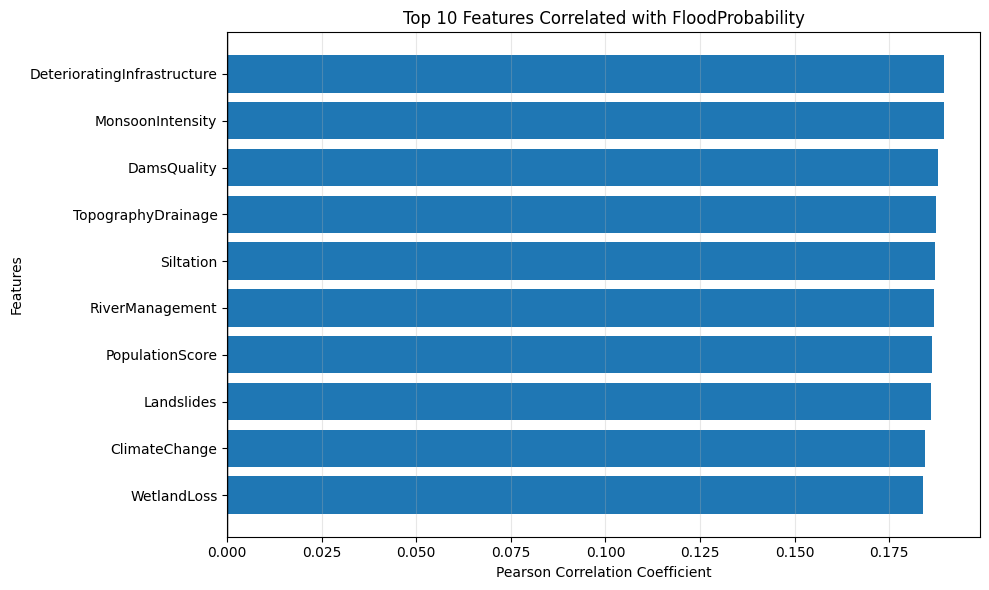

In [22]:

# STEP 13：特徵相關性分析
# Data Understanding 補充

import matplotlib.pyplot as plt

# 1. 使用訓練集計算特徵與洪水機率的相關係數
correlations = X_train.corrwith(y_train)

# 2. 依相關係數絕對值排序
sorted_index = correlations.abs().sort_values(
    ascending=False
).index

correlations = correlations.loc[sorted_index]

print("========== 特徵相關性排名 ==========")
display(correlations.to_frame(name="Correlation"))

# 3. 繪製前 10 個特徵的相關性長條圖
top10 = correlations.head(10).iloc[::-1]

plt.figure(figsize=(10, 6))
plt.barh(top10.index, top10.values)

plt.axvline(0, color="black", linewidth=1)
plt.title("Top 10 Features Correlated with FloodProbability")
plt.xlabel("Pearson Correlation Coefficient")
plt.ylabel("Features")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()


### 特徵相關性分析

本研究使用 Pearson 相關係數分析各項特徵與洪水機率（FloodProbability）之間的線性關係。

根據分析結果，相關性最高的前三個特徵分別為 DeterioratingInfrastructure（基礎設施老化）、MonsoonIntensity（季風強度）以及 DamsQuality（水壩品質）。

從圖表可以觀察到，前十個特徵的相關係數大約介於 0.18 至 0.19 之間，顯示各項特徵與洪水機率具有偏弱的正向線性相關。

然而，使用全部 20 個特徵建立的多元線性回歸模型，其 R² 達到 0.844877，明顯高於只使用 15 個特徵的模型（R² = 0.595773）。

因此，本研究認為，雖然單一特徵的線性相關程度有限，但結合多個特徵仍能提升模型的預測表現。此外，特徵選擇不一定能提高模型準確度，仍需要透過實際評估結果進行比較。


## 4. Modeling（模型建立）

### 模型建立目的
本研究使用多元線性回歸（Multiple Linear Regression）預測洪水機率，並比較不同特徵數量對模型預測能力的影響。

### 特徵選擇（Feature Selection）
本研究使用 SelectKBest 搭配 f_regression 進行特徵選擇。

SelectKBest 會根據特徵與預測目標之間的單變數 F 分數進行排名，選出分數較高的特徵。

本研究從原本 20 個特徵中選出 15 個，減少 25% 的特徵數量。

根據特徵選擇結果，F 分數最高的前三個特徵為：

1. DeterioratingInfrastructure（基礎設施老化）
2. MonsoonIntensity（季風強度）
3. DamsQuality（水壩品質）

### 多元線性回歸模型
使用 sklearn.linear_model 中的 LinearRegression 建立兩個模型：

- 模型 A：使用全部 20 個特徵進行訓練。
- 模型 B：使用 SelectKBest 選出的 15 個特徵進行訓練。

兩個模型都使用相同的訓練集與測試集，以確保比較公平。

### 模型比較目的
透過比較兩個模型的 MAE、MSE、RMSE 與 R²，觀察特徵數量減少後是否能維持或提升預測能力。

本研究也希望了解特徵選擇是否一定能改善多元線性回歸的表現。


In [23]:

# STEP 7：Feature Selection（特徵選擇）

from sklearn.feature_selection import SelectKBest, f_regression

# 1. 使用 SelectKBest 選出 15 個特徵
selector = SelectKBest(score_func=f_regression, k=15)

# 只使用訓練集進行特徵選擇
selector.fit(X_train, y_train)

# 2. 取得被選中的特徵名稱
selected_features = X_train.columns[selector.get_support()].tolist()

print("原始特徵數量：", X_train.shape[1])
print("選擇後特徵數量：", len(selected_features))

print("\n選中的 15 個特徵：")
for feature in selected_features:
    print(feature)

# 3. 顯示所有特徵的 F 分數排名
feature_scores = pd.DataFrame({
    '特徵名稱': X_train.columns,
    'F分數': selector.scores_
}).sort_values(by='F分數', ascending=False)

print("\n特徵重要程度排名：")
display(feature_scores)

# 4. 建立篩選後的訓練集與測試集
X_train_selected = X_train[selected_features]
X_test_selected = X_test[selected_features]

print("\n篩選後訓練集：", X_train_selected.shape)
print("篩選後測試集：", X_test_selected.shape)


原始特徵數量： 20
選擇後特徵數量： 15

選中的 15 個特徵：
MonsoonIntensity
TopographyDrainage
RiverManagement
Deforestation
ClimateChange
DamsQuality
Siltation
AgriculturalPractices
IneffectiveDisasterPreparedness
Landslides
Watersheds
DeterioratingInfrastructure
PopulationScore
WetlandLoss
PoliticalFactors

特徵重要程度排名：


,特徵名稱,F分數
15,DeterioratingInfrastructure,33324.882198
0,MonsoonIntensity,33276.472476
6,DamsQuality,32774.785377
1,TopographyDrainage,32562.795907
7,Siltation,32493.001851
2,RiverManagement,32366.566651
16,PopulationScore,32192.796924
13,Landslides,32075.318913
5,ClimateChange,31510.513402
17,WetlandLoss,31316.131784



篩選後訓練集： (894365, 15)
篩選後測試集： (223592, 15)


In [24]:

# STEP 8：Modeling（模型建立）

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# ===== 模型 A：使用全部 20 個特徵 =====

model_all = LinearRegression()

# 訓練模型
model_all.fit(X_train, y_train)

# 預測測試集
y_pred_all = model_all.predict(X_test)

print("模型 A（20 個特徵）訓練完成！")


# ===== 模型 B：使用篩選後 15 個特徵 =====

model_selected = LinearRegression()

# 訓練模型
model_selected.fit(X_train_selected, y_train)

# 預測測試集
y_pred_selected = model_selected.predict(X_test_selected)

print("模型 B（15 個特徵）訓練完成！")


# ===== 比較兩個模型的預測效果 =====

def evaluate_model(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mean_squared_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R²": r2_score(y_true, y_pred)
    }

results = pd.DataFrame({
    "模型 A（20 個特徵）": evaluate_model(y_test, y_pred_all),
    "模型 B（15 個特徵）": evaluate_model(y_test, y_pred_selected)
})

print("\n========== 模型比較結果 ==========")
display(results.round(6))


模型 A（20 個特徵）訓練完成！
模型 B（15 個特徵）訓練完成！

========== 模型比較結果 ==========


,模型 A（20 個特徵）,模型 B（15 個特徵）
MAE,0.015792,0.026109
MSE,0.000403,0.001051
RMSE,0.020080,0.032414
R²,0.844877,0.595773



## 5. Evaluation（模型評估）

### 模型評估目的
本研究透過 MAE、MSE、RMSE 和 R² 四種評估指標，比較使用全部 20 個特徵的模型 A，以及選擇 15 個特徵的模型 B。

### 模型評估結果

| 評估指標 | 模型 A（20 個特徵） | 模型 B（15 個特徵） |
|---|---|---|
| MAE | 0.015792 | 0.026109 |
| MSE | 0.000403 | 0.001051 |
| RMSE | 0.020080 | 0.032414 |
| R² | 0.844877 | 0.595773 |

### 評估結果分析
根據測試集的結果，模型 A 的 MAE、MSE 和 RMSE 均低於模型 B，表示模型 A 的預測誤差較小。

此外，模型 A 的 R² 為 0.844877，代表模型可以解釋測試資料中約 84.49% 的目標變異；模型 B 的 R² 則為 0.595773。

因此，使用全部 20 個特徵的模型 A 表現明顯優於只使用 15 個特徵的模型 B。

### 預測結果視覺化
本研究繪製實際值與預測值的散佈圖，並以紅色虛線表示理想預測情況。

從圖表可以觀察到，模型 A 的預測點較集中於理想線附近，而模型 B 的預測點分布較為分散。

此結果與模型評估指標一致，顯示模型 A 具有較好的預測能力。

### 95% 預測區間
本研究使用 OLS 模型計算 95% 預測區間，並隨機抽取 100 筆測試資料進行視覺化。

結果顯示，100 筆樣本中有 95 筆實際值落在預測區間內，抽樣涵蓋率為 95%。

需要注意，預測區間的統計解釋依賴線性回歸模型的相關假設，而抽樣涵蓋率不代表所有未來資料都一定具有相同結果。

### 研究結論
本研究發現，減少特徵數量不一定能提升模型預測準確度。

雖然 SelectKBest 成功將特徵從 20 個減少到 15 個，但模型的 R² 明顯下降。

因此，進行特徵選擇時，除了考慮降低模型複雜度，也需要透過實際測試結果評估是否影響預測能力。

綜合評估結果，本研究選擇模型 A（20 個特徵）作為較適合本資料集的最終模型。


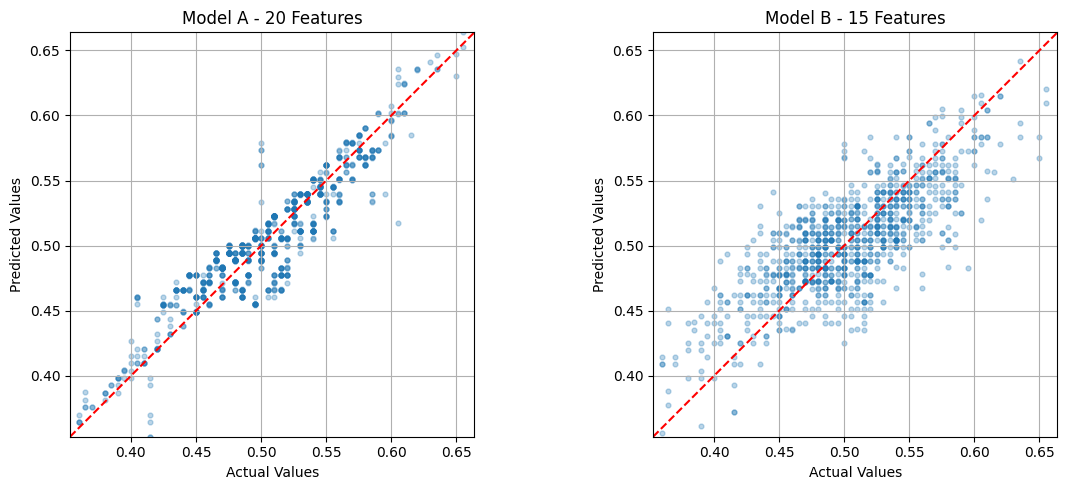

In [25]:

# STEP 9：Evaluation（預測結果視覺化）

import matplotlib.pyplot as plt
import numpy as np

# 隨機抽取 1000 筆測試資料用於繪圖
rng = np.random.default_rng(42)
sample_idx = rng.choice(len(y_test), size=1000, replace=False)

actual = y_test.iloc[sample_idx].to_numpy()
pred_a = y_pred_all[sample_idx]
pred_b = y_pred_selected[sample_idx]

# 建立兩張比較圖
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

low = min(actual.min(), pred_a.min(), pred_b.min())
high = max(actual.max(), pred_a.max(), pred_b.max())

# 模型 A
axes[0].scatter(actual, pred_a, alpha=0.3, s=12)
axes[0].plot([low, high], [low, high], 'r--')
axes[0].set_title("Model A - 20 Features")
axes[0].set_xlabel("Actual Values")
axes[0].set_ylabel("Predicted Values")
axes[0].grid(True)

# 模型 B
axes[1].scatter(actual, pred_b, alpha=0.3, s=12)
axes[1].plot([low, high], [low, high], 'r--')
axes[1].set_title("Model B - 15 Features")
axes[1].set_xlabel("Actual Values")
axes[1].set_ylabel("Predicted Values")
axes[1].grid(True)

# 保持兩張圖的刻度一致
for ax in axes:
    ax.set_xlim(low, high)
    ax.set_ylim(low, high)
    ax.set_aspect('equal', adjustable='box')

plt.tight_layout()
plt.show()


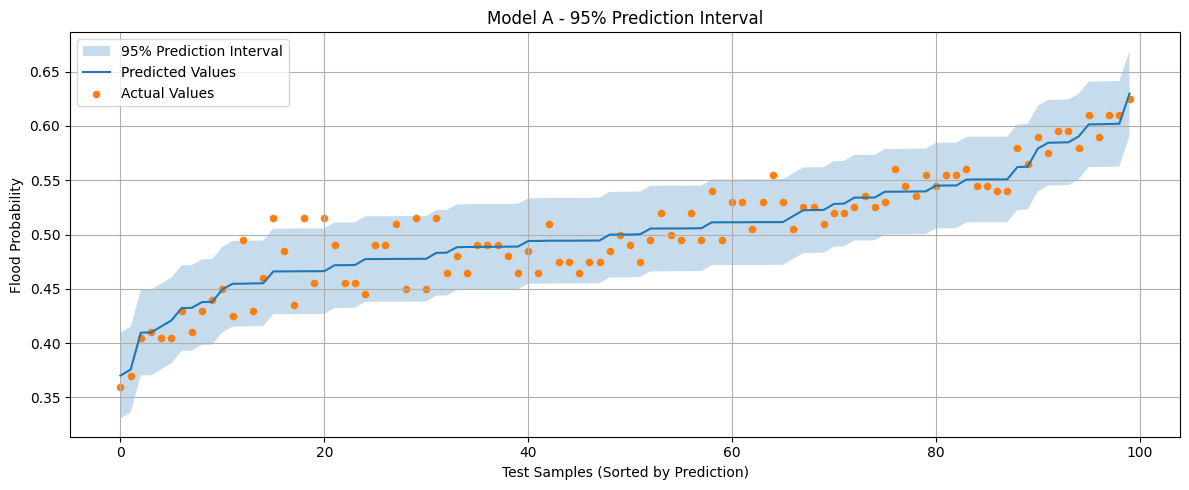

抽樣資料區間涵蓋率： 95.0 %


In [26]:

# STEP 10：95% 預測區間（Prediction Interval）

import statsmodels.api as sm
import numpy as np
import matplotlib.pyplot as plt

# 1. 使用全部 20 個特徵建立 OLS 線性回歸模型
X_train_sm = sm.add_constant(X_train, has_constant='add')
ols_model = sm.OLS(y_train, X_train_sm).fit()

# 2. 從測試集抽出 100 筆資料
rng = np.random.default_rng(42)
sample_idx = rng.choice(len(X_test), size=100, replace=False)

X_sample = X_test.iloc[sample_idx]
y_sample = y_test.iloc[sample_idx].to_numpy()

# 3. 計算 95% 預測區間
X_sample_sm = sm.add_constant(X_sample, has_constant='add')

prediction = ols_model.get_prediction(X_sample_sm)
summary = prediction.summary_frame(alpha=0.05)

predicted = summary['mean'].to_numpy()
lower = summary['obs_ci_lower'].to_numpy()
upper = summary['obs_ci_upper'].to_numpy()

# 4. 依照預測值排序
order = np.argsort(predicted)
x_axis = np.arange(len(order))

# 5. 繪圖
plt.figure(figsize=(12, 5))

plt.fill_between(
    x_axis, lower[order], upper[order],
    alpha=0.25, label='95% Prediction Interval'
)

plt.plot(
    x_axis, predicted[order],
    label='Predicted Values'
)

plt.scatter(
    x_axis, y_sample[order],
    s=20, label='Actual Values'
)

plt.title('Model A - 95% Prediction Interval')
plt.xlabel('Test Samples (Sorted by Prediction)')
plt.ylabel('Flood Probability')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# 6. 計算抽樣資料的區間涵蓋比例
coverage = np.mean(
    (y_sample >= lower) & (y_sample <= upper)
)

print("抽樣資料區間涵蓋率：", round(coverage * 100, 2), "%")



## 6. Deployment（模型應用）

### 模型應用目的
本研究完成多元線性回歸模型的訓練與評估後，進一步示範如何使用訓練好的模型，對新的資料進行洪水機率預測。

### 最終模型選擇
根據 Evaluation 階段的結果，模型 A（20 個特徵）的 R² 為 0.844877，優於模型 B（15 個特徵）的 0.595773。

因此，本研究選擇模型 A 作為最終模型。

### 新資料預測方式
本研究使用訓練集各特徵的中位數，建立一筆模擬資料，並分別使用模型 A 與模型 B 進行預測。

### 新資料預測結果

| 模型 | 預測值 |
|---|---|
| 模型 A（20 個特徵） | 0.5113 |
| 模型 B（15 個特徵） | 0.5095 |

### 結果分析
兩個模型對同一筆模擬資料的預測結果相近，預測值相差 0.0018。

然而，單筆資料的預測結果不能代表模型整體準確度，因此仍需參考測試集的 MAE、MSE、RMSE 與 R² 指標。

### 實際應用與限制
本研究目前僅在 Google Colab 中完成模型應用示範，尚未部署至實際網站或洪水預警系統。

此外，本研究使用的是 Kaggle 競賽資料，模型輸出不應直接視為真實環境中已校準的洪水發生機率。

未來可使用實際氣象、水文與地理資料進行額外驗證，再評估是否適合應用於洪水風險分析系統。


In [27]:

# STEP 12：Deployment（模型應用示範）

# 1. 使用訓練集各特徵的中位數，建立一筆模擬資料
new_data = X_train.median().to_frame().T

# 2. 使用模型 A（20 個特徵）預測
prediction_a = model_all.predict(new_data)

# 3. 使用模型 B（15 個特徵）預測
new_data_selected = new_data[selected_features]
prediction_b = model_selected.predict(new_data_selected)

# 4. 顯示預測結果
print("========== 新資料預測結果 ==========")

print("模型 A（20 個特徵）預測值：",
      round(prediction_a[0], 4))

print("模型 B（15 個特徵）預測值：",
      round(prediction_b[0], 4))

# 5. 顯示輸入的模擬資料
print("\n========== 模擬資料 ==========")
display(new_data)


========== 新資料預測結果 ==========
模型 A（20 個特徵）預測值： 0.5113
模型 B（15 個特徵）預測值： 0.5095

========== 模擬資料 ==========


,MonsoonIntensity,TopographyDrainage,RiverManagement,Deforestation,Urbanization,ClimateChange,DamsQuality,Siltation,AgriculturalPractices,Encroachments,IneffectiveDisasterPreparedness,DrainageSystems,CoastalVulnerability,Landslides,Watersheds,DeterioratingInfrastructure,PopulationScore,WetlandLoss,InadequatePlanning,PoliticalFactors
0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0
